<p style="text-align:center"><img src="../../../Images/Banner/08_web_gis.png" alt="Web and Cloud GIS" width="100%"></p>

# Cloud Platforms: Planetary Computer, Earth Engine and Copernicus openEO

Petabytes of Earth observation data now sit in public clouds next to computers you can rent.
Several platforms package that data, and they differ in where your code runs:

- **Catalogue plus your own compute.** Microsoft Planetary Computer, Earth Search on AWS and the
  Copernicus Data Space Ecosystem publish STAC catalogues of cloud-optimised files. You read them
  with open tools (pystac-client, odc-stac, rasterio, `geolattice`) from your laptop or, better, from a
  machine in the same region.
- **Server-side processing.** Google Earth Engine and openEO (on Copernicus Data Space and other
  back ends) accept a description of the computation and run it on their infrastructure; only
  results come back.

This notebook works through each kind on Bangladesh. It compares three STAC catalogues on the same
query, finds that they deliver **different numbers for the same Sentinel-2 pixels**, builds a
cloud-free NDVI composite with odc-stac, summarises land cover, elevation and surface water for a
haor district from Planetary Computer, and expresses the same composite as an openEO process graph
and as Earth Engine code.



### Learning objectives

1. Distinguish catalogue-based from server-side cloud platforms, and what each costs in access, egress and lock-in.
2. Search several STAC catalogues for the same data and compare what they return.
3. Detect and correct differences in how providers store Sentinel-2 reflectance (the BOA offset).
4. Load STAC items lazily into xarray with odc-stac, mask clouds and build composites.
5. Use analysis-ready global datasets (ESA WorldCover, Copernicus DEM, JRC Global Surface Water).
6. Express the same analysis for openEO and Earth Engine, and judge when to use them.



### Data

| Data | Platform |
|---|---|
| Sentinel-2 L2A, January-March 2024, over Bogra town and surrounding rice land | Planetary Computer, Earth Search (AWS), Copernicus Data Space |
| ESA WorldCover 2021 (10 m), Copernicus DEM GLO-30, JRC Global Surface Water | Planetary Computer |
| District boundaries of Bangladesh | `Data/00_shared/data_web_cloud_gis/08_03_outputs/districts.gpkg` (Notebook 08_03) |

Everything in this notebook runs without an account except the execution of the openEO and Earth
Engine computations, which need free registrations (Sections 7 and 8 explain how to enable them).
Install: `pip install pystac-client planetary-computer odc-stac openeo earthengine-api`.



### Contents

1. Setup
2. The platform landscape
3. Three catalogues, one question
4. Same scene, different numbers: the Sentinel-2 offset
5. Compute next to the catalogue: a cloud-free composite with odc-stac
6. Beyond imagery: ready-made global layers for a haor district
7. Server-side processing with openEO
8. Google Earth Engine
9. Choosing a platform
10. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `geolattice[rsense-biopar]`, which no GeoLattice option installs: `pip install "geolattice[rsense-biopar]"`.

In [1]:
# Imports, plot defaults, and output folder for this notebook
%matplotlib inline
import json
import os
import shutil
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Geospatial and cloud-STAC stack used below
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
import pystac_client
import planetary_computer
import odc.stac
import rioxarray  # noqa: F401  (adds .rio to xarray)
import openeo
import ee

import geolattice
import geolattice.web as web

plt.rcParams.update({"figure.dpi": 110})
DATA = Path("../../../Data")
WEB = DATA / "00_shared" / "data_web_cloud_gis"
OUT = WEB / "08_09_outputs"
# Fresh output directory each run; districts come from Notebook 08_03
if OUT.exists():
    shutil.rmtree(OUT)
OUT.mkdir(parents=True)
if not (WEB / "08_03_outputs" / "districts.gpkg").exists():
    raise FileNotFoundError("districts.gpkg is missing: run Notebook 08_03 first")

AOI = [89.30, 24.80, 89.42, 24.90]            # 12 x 11 km: Bogra town and the rice land around it
SEASON = "2024-01-01/2024-03-31"              # dry (Boro rice) season
print("geolattice", geolattice.__version__, "| odc-stac", odc.stac.__version__, "| openeo", openeo.__version__, "| earthengine-api", ee.__version__)


geolattice 0.3.11 | odc-stac 0.5.3 | openeo 0.53.0 | earthengine-api 1.7.49


## The platform landscape

| Platform | Data | Where the code runs | Access | Cost to you |
|---|---|---|---|---|
| **Microsoft Planetary Computer** | ~130 datasets as COG, Zarr, GeoParquet; STAC API | Anywhere; fastest in Azure West Europe | Anonymous, URLs signed by `planetary-computer` | Free data; your compute; egress is Microsoft's |
| **Earth Search (Element 84, AWS Open Data)** | Sentinel-1/2, Landsat, Copernicus DEM, NAIP as COGs; STAC API | Anywhere; fastest in AWS us-west-2 | Anonymous | Free data; your compute |
| **Copernicus Data Space Ecosystem (CDSE)** | The complete Copernicus archive; STAC API; S3 | Anywhere; or its JupyterHub, openEO, Sentinel Hub | Free account for downloads and processing | Free quotas, paid beyond |
| **Google Earth Engine** | Multi-petabyte catalogue, ingested into Google's own format | Google's servers (server-side API) | Google Cloud project, registered for Earth Engine | Free for non-commercial and research use; commercial licences |
| **openEO** (CDSE, VITO, EODC, ...) | The back end's collections | The back end's servers, through a standard API | Account with the back end | Credits; free tier on CDSE |
| **AWS / Azure / GCP compute** | Any of the above | Virtual machines, Kubernetes, batch, serverless | Cloud account | Pay for compute; read data in the same region |

The trade-off: catalogue platforms give you the files and complete freedom over the analysis, with
open tools that move between providers; server-side platforms remove data handling and scale
automatically, but the analysis is written in their API and runs only there.

## Three catalogues, one question

The same search on three STAC APIs: Sentinel-2 L2A scenes over the Bogra area, January to March
2024, under 5 % cloud.

In [2]:
# Search three STAC catalogues for the same Sentinel-2 season and AOI
catalogues = {
    "Planetary Computer": ("https://planetarycomputer.microsoft.com/api/stac/v1", planetary_computer.sign_inplace, "B04"),
    "Earth Search (AWS)": ("https://earth-search.aws.element84.com/v1", None, "red"),
    "Copernicus Data Space": ("https://stac.dataspace.copernicus.eu/v1", None, "B04_10m"),
}
found, rows = {}, []
for name, (url, modifier, red) in catalogues.items():
    t0 = time.perf_counter()
    try:
        # Open the catalogue and keep scenes with cloud cover under 5 %
        client = pystac_client.Client.open(url, modifier=modifier)
        items = sorted(client.search(collections=["sentinel-2-l2a"], bbox=AOI, datetime=SEASON,
                                     query={"eo:cloud_cover": {"lt": 5}}).items(), key=lambda i: i.datetime)
    except Exception as exc:
        print(name, "failed:", type(exc).__name__, exc); continue
    seconds = time.perf_counter() - t0
    found[name] = items
    # Summarize hit count, timing, dates, and where the red band is hosted
    href = items[0].assets[red].href
    rows.append({"catalogue": name, "scenes": len(items), "search s": round(seconds, 1),
                 "dates": ", ".join(sorted({i.datetime.strftime("%m-%d") for i in items})),
                 "red band served as": href.split("://")[0] + "://" + href.split("/")[2][:38] + "...",
                 "first scene id": items[0].id})
pd.DataFrame(rows).set_index("catalogue")


,scenes,search s,dates,red band served as,first scene id
catalogue,,,,,
Planetary Computer,7,1.6,"01-04, 02-03, 02-18, 02-23, 02-28, 03-09",https://sentinel2l2a01.blob.core.windows.net...,S2B_MSIL2A_20240104T044209_R033_T45RYH_2024010...
Earth Search (AWS),6,0.8,"01-04, 02-03, 02-18, 02-23, 02-28, 03-09",https://sentinel-cogs.s3.us-west-2.amazonaws.c...,S2B_45RYH_20240104_0_L2A
Copernicus Data Space,6,2.3,"01-04, 02-03, 02-18, 02-23, 02-28, 03-09",s3://eodata...,S2B_MSIL2A_20240104T044209_N0510_R033_T45RYH_2...


All three catalogues answered in 0.8-2.3 s and found the same six acquisition dates, but they are not
the same thing:

- **Planetary Computer** returned 7 items for 6 dates: one date is listed twice, as two processing
  runs of the same acquisition. Its files are on Azure Blob Storage, reached through signed URLs.
- **Earth Search** returned 6 items with short identifiers, and public HTTPS URLs on S3.
- **Copernicus Data Space** returned 6 items whose files are `s3://eodata` paths, which need CDSE
  credentials to read.

A pipeline that mixes catalogues has to deduplicate by acquisition, not by item ID.

## Same scene, different numbers: the Sentinel-2 offset

Since processing baseline 04.00 (January 2022), ESA stores Sentinel-2 L2A reflectance with an
offset: reflectance = (DN − 1000) / 10000, so that dark pixels are not clipped at zero. Providers
handle this differently. We read the same 12 × 11 km window of the red and near-infrared bands of
the same scene (9 March 2024) from Planetary Computer and Earth Search.

In [3]:
# Pick the latest date present in both Planetary Computer and Earth Search
pc_items = {i.datetime.date(): i for i in found["Planetary Computer"]}
es_items = {i.datetime.date(): i for i in found["Earth Search (AWS)"]}
day = sorted(set(pc_items) & set(es_items))[-1]
pc_item, es_item = pc_items[day], es_items[day]

# Window-read one band over the AOI without downloading the full COG
def window(href):
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", AWS_NO_SIGN_REQUEST="YES"):
        with rasterio.open(href) as src:
            return src.read(1, window=from_bounds(*transform_bounds(4326, src.crs, *AOI), src.transform)).astype("float64")

bands = {"PC red": window(pc_item.assets["B04"].href), "PC nir": window(pc_item.assets["B08"].href),
         "ES red": window(es_item.assets["red"].href), "ES nir": window(es_item.assets["nir"].href)}
# Compare digital numbers where both catalogues have valid pixels
valid = np.all([b > 0 for b in bands.values()], axis=0)
diff = bands["PC red"][valid] - bands["ES red"][valid]
print(f"scene {day}: PC {pc_item.id} | ES {es_item.id}")
print(f"processing baseline: PC {pc_item.properties.get('s2:processing_baseline')}, ES {es_item.properties.get('s2:processing_baseline')}; "
      f"ES 'earthsearch:boa_offset_applied' = {es_item.properties.get('earthsearch:boa_offset_applied')}")
print(f"PC red minus ES red: median {np.median(diff):.0f}, range {diff.min():.0f} to {diff.max():.0f} (DN), {valid.sum():,} pixels")
print("ES metadata for the red band:", es_item.assets["red"].extra_fields.get("raster:bands"))


scene 2024-03-09: PC S2A_MSIL2A_20240309T043701_R033_T45RYH_20240309T091651 | ES S2A_45RYH_20240309_0_L2A
processing baseline: PC 05.10, ES 05.10; ES 'earthsearch:boa_offset_applied' = True
PC red minus ES red: median 1000, range 800 to 1288 (DN), 1,390,928 pixels
ES metadata for the red band: [{'nodata': 0, 'data_type': 'uint16', 'bits_per_sample': 15, 'spatial_resolution': 10, 'scale': 0.0001, 'offset': -0.1}]


In [4]:
# NDVI from the same pixels under correct and incorrect reflectance recipes
def ndvi(red, nir):
    return (nir - red) / (nir + red)

recipes = {
    "PC, DN used as is (wrong)": ndvi(bands["PC red"], bands["PC nir"]),
    "PC, (DN - 1000) / 10000 (correct)": ndvi(bands["PC red"] - 1000, bands["PC nir"] - 1000),
    "ES, DN / 10000 (correct: offset already applied)": ndvi(bands["ES red"], bands["ES nir"]),
    "ES, metadata scale and offset applied (wrong: offset twice)": ndvi(bands["ES red"] * 1e-4 - 0.1, bands["ES nir"] * 1e-4 - 0.1),
}
# Score each recipe against the correct Earth Search scaling
reference = recipes["ES, DN / 10000 (correct: offset already applied)"][valid]
rows = []
for name, v in recipes.items():
    v = v[valid]
    ok = np.isfinite(v) & (np.abs(v) <= 1)
    rows.append({"recipe": name, "median NDVI": np.median(v[ok]), "median abs. difference from correct": np.median(np.abs(v - reference)),
                 "impossible values (|NDVI| > 1 or infinite)": 1 - ok.mean(), "share of pixels NDVI > 0.5": (v[ok] > 0.5).mean()})
pd.DataFrame(rows).set_index("recipe").round(3)


,median NDVI,median abs. difference from correct,impossible values (|NDVI| > 1 or infinite),share of pixels NDVI > 0.5
recipe,,,,
"PC, DN used as is (wrong)",0.224,0.179,0.00,0.013
"PC, (DN - 1000) / 10000 (correct)",0.406,0.000,0.00,0.349
"ES, DN / 10000 (correct: offset already applied)",0.406,0.000,0.00,0.349
"ES, metadata scale and offset applied (wrong: offset twice)",0.573,1.433,0.77,0.578


The two copies of the same scene, at the same processing baseline (05.10), differ by a median of
**exactly 1,000 DN**:

- **Planetary Computer** delivers ESA's original values, with the offset still in them.
- **Earth Search** has subtracted it (`boa_offset_applied: true`), yet its STAC metadata still
  advertises `offset: -0.1`.

Individual pixels differ by 800 to 1,288, so the two copies are not bit-identical apart from the
offset either.

The consequences for NDVI:

| Recipe | Median NDVI | Pixels above 0.5 |
|---|---|---|
| Correct, from either source | 0.406 | 34.9% |
| Planetary Computer DN used as is | 0.224 | 1.3% |
| Earth Search metadata offset applied (offset subtracted twice) |: (77% of pixels impossible) | n/a |

Using Planetary Computer's DN as is understates NDVI by 0.18. With the offset subtracted twice,
77% of pixels get impossible NDVI values (beyond ±1 or infinite).

The rule: read `s2:processing_baseline` and the provider's offset convention, and test one scene
from each source before mixing them.

## Compute next to the catalogue: a cloud-free composite with odc-stac

`odc.stac.load` turns a list of STAC items into an xarray Dataset on a common grid, lazily with
Dask: only the requested bands and only the area of interest are read. We load all Planetary
Computer scenes of the season with up to 20 % cloud, mask clouds, shadows and water with the
scene classification layer (SCL), apply the offset, and take the per-pixel median NDVI.

In [5]:
# Lazy-load a multi-date Sentinel-2 cube over the AOI with odc-stac
pcc = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
items = list(pcc.search(collections=["sentinel-2-l2a"], bbox=AOI, datetime=SEASON, query={"eo:cloud_cover": {"lt": 20}}).items())
t0 = time.perf_counter()
cube = odc.stac.load(items, bands=["B02", "B03", "B04", "B08", "SCL"], bbox=AOI, resolution=10, crs="EPSG:32645",
                     chunks={}, groupby="solar_day", dtype="uint16")
print(f"{len(items)} items -> {cube.sizes['time']} dates, {cube.sizes['y']} x {cube.sizes['x']} pixels; "
      f"lazy dataset of {cube.nbytes / 1e6:.0f} MB defined in {time.perf_counter() - t0:.2f} s")
t0 = time.perf_counter()
cube = cube.compute()
print(f"read in {time.perf_counter() - t0:.1f} s")

# Mask to clear land, convert DN to reflectance, then build a median NDVI composite
clear = cube.SCL.isin([4, 5])                                     # SCL 4 vegetation, 5 bare soil
refl = {b: ((cube[b].astype("float32") - 1000) / 1e4).where(clear) for b in ["B02", "B03", "B04", "B08"]}
nd = (refl["B08"] - refl["B04"]) / (refl["B08"] + refl["B04"])
composite = nd.median("time")
n_clear = clear.sum("time")
scl_share = pd.Series(cube.SCL.values.ravel()).map({0: "no data", 1: "saturated", 2: "dark", 3: "cloud shadow", 4: "vegetation",
                                                     5: "bare soil", 6: "water", 7: "unclassified", 8: "cloud (medium)",
                                                     9: "cloud (high)", 10: "thin cirrus", 11: "snow"}).value_counts(normalize=True)
print("scene classification over all dates:", (scl_share * 100).round(1).head(6).to_dict())
print(f"clear observations per pixel: median {int(n_clear.median())}, min {int(n_clear.min())}; median composite NDVI {float(composite.median()):.3f}")


10 items -> 9 dates, 1129 x 1233 pixels; lazy dataset of 125 MB defined in 0.02 s


read in 18.5 s


scene classification over all dates: {'bare soil': 79.4, 'vegetation': 16.2, 'unclassified': 2.5, 'cloud (medium)': 0.6, 'water': 0.5, 'thin cirrus': 0.4}
clear observations per pixel: median 9, min 0; median composite NDVI 0.449


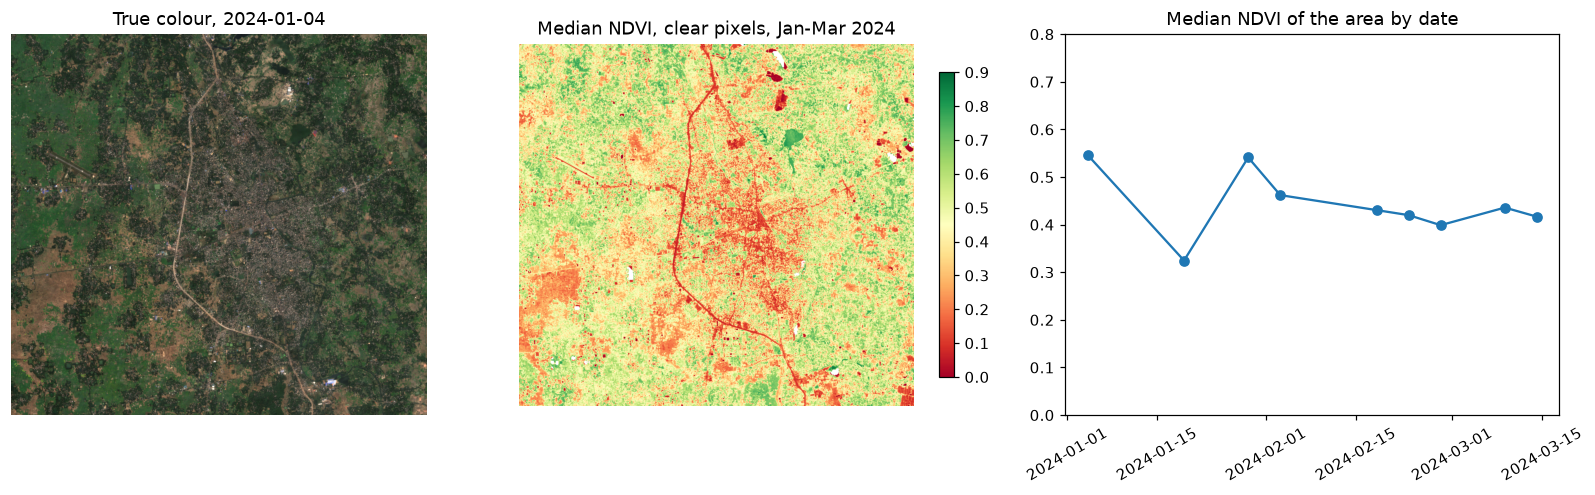

../../../data/data_web_cloud_gis/08_09_outputs/bogra_ndvi_median_2024q1_cog.tif: valid Cloud-Optimized GeoTIFF


In [6]:
# Plot true colour, median NDVI, and the area NDVI time series
best = int(clear.mean(("x", "y")).argmax())
rgb = np.stack([(cube[b].isel(time=best).astype("float32") - 1000) / 1e4 for b in ["B04", "B03", "B02"]], axis=-1)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].imshow(np.clip(rgb / 0.25, 0, 1)); ax[0].set_title(f"True colour, {str(cube.time.values[best])[:10]}")
im = ax[1].imshow(composite, cmap="RdYlGn", vmin=0, vmax=0.9); ax[1].set_title("Median NDVI, clear pixels, Jan-Mar 2024")
fig.colorbar(im, ax=ax[1], shrink=0.8)
monthly = nd.median(("x", "y")).to_series()
ax[2].plot(monthly.index, monthly.values, "o-"); ax[2].set_title("Median NDVI of the area by date"); ax[2].set_ylim(0, 0.8)
ax[2].tick_params(axis="x", rotation=30)
for a in ax[:2]:
    a.set_axis_off()
plt.tight_layout(); plt.show()
# Write GeoTIFF then convert and validate a Cloud Optimized GeoTIFF
composite.rio.write_crs("EPSG:32645").rio.to_raster(OUT / "bogra_ndvi_median_2024q1.tif", compress="deflate")
print(web.validate_cog(web.to_cog(OUT / "bogra_ndvi_median_2024q1.tif", OUT / "bogra_ndvi_median_2024q1_cog.tif")))


odc-stac defined a 125 MB lazy dataset (9 dates, 1,129 × 1,233 pixels at 10 m) in 0.02 s and read
it from Azure in 18.5 s. The scene classification shows the dry season: 79.4% of observations are
classed bare soil, which includes freshly transplanted and irrigated Boro fields, and 16.2%
vegetation. Clouds were rare, so every pixel had a median of 9 clear observations.

The median composite (NDVI 0.449) separates Bogra town and the main roads (red) from the
surrounding fields and village groves (green). The date series dips on 18 January, probably from
winter haze. The composite was saved as a GeoTIFF and converted with `geolattice.web.to_cog` into a
valid COG, ready for the tile server of Notebook 08_05.

## Beyond imagery: ready-made global layers for a haor district

Planetary Computer also hosts analysis-ready global products. For Sunamganj district, in the haor
basin of the north-east, we load three of them at 30 m: **ESA WorldCover 2021** (land cover),
**Copernicus DEM GLO-30** (elevation) and **JRC Global Surface Water** occurrence (the share of
1984-2020 Landsat observations in which each pixel was water).

In [7]:
# Load Sunamganj districts and pull three global layers from Planetary Computer
districts = gpd.read_file(WEB / "08_03_outputs" / "districts.gpkg")
sun = districts[districts.district == "Sunamganj"]
bbox = list(sun.total_bounds)
layers = {"esa-worldcover": ("map", "nearest"), "cop-dem-glo-30": ("data", "bilinear"), "jrc-gsw": ("occurrence", "nearest")}
grids, rows = {}, []
for collection, (asset, resampling) in layers.items():
    t0 = time.perf_counter()
    its = list(pcc.search(collections=[collection], bbox=bbox).items())
    if collection == "esa-worldcover":
        its = [i for i in its if "2021" in i.id]
    ds = odc.stac.load(its, bands=[asset], bbox=bbox, resolution=30, crs="EPSG:32646", resampling=resampling,
                       chunks={}).isel(time=0)
    grid = ds[asset].compute()
    grids[collection] = grid
    rows.append({"layer": collection, "items": len(its), "grid": f"{grid.sizes['y']} x {grid.sizes['x']}", "seconds": round(time.perf_counter() - t0, 1)})
display(pd.DataFrame(rows).set_index("layer"))

# Restrict raster stats to the district polygon
from rasterio.features import geometry_mask
g0 = grids["esa-worldcover"]
inside = geometry_mask([sun.to_crs(32646).geometry.iloc[0]], out_shape=g0.shape, transform=g0.odc.geobox.affine, invert=True)
classes = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland", 50: "Built-up", 60: "Bare / sparse",
           70: "Snow and ice", 80: "Permanent water", 90: "Herbaceous wetland", 95: "Mangroves", 100: "Moss and lichen"}
lc = pd.Series(g0.values[inside]).map(classes).value_counts(normalize=True).mul(100).round(1)
dem = grids["cop-dem-glo-30"].values[inside]
occ_grid = grids["jrc-gsw"].values.astype(float)
occ_grid[occ_grid > 100] = np.nan                                   # 255 = no data
occ = occ_grid[inside]
print(f"Sunamganj district: {inside.sum() * 900 / 1e6:,.0f} km² at 30 m")
print("land cover (%):", lc.to_dict())
print(f"elevation: median {np.median(dem):.1f} m, 90 % of the district below {np.percentile(dem, 90):.1f} m")
print(f"surface water: {np.nanmean(occ > 0):.1%} of the district was ever water (1984-2020); {np.nanmean(occ >= 50):.1%} is water at least half the time")


,items,grid,seconds
layer,,,
esa-worldcover,1,2391 x 2748,3.1
cop-dem-glo-30,4,2391 x 2748,19.5
jrc-gsw,1,2391 x 2748,3.5


Sunamganj district: 3,693 km² at 30 m
land cover (%): {'Cropland': 57.6, 'Herbaceous wetland': 21.4, 'Tree cover': 12.7, 'Permanent water': 6.5, 'Grassland': 1.3, 'Built-up': 0.3, 'Bare / sparse': 0.2, 'Shrubland': 0.0}
elevation: median 5.1 m, 90 % of the district below 9.8 m
surface water: 78.7% of the district was ever water (1984-2020); 36.4% is water at least half the time


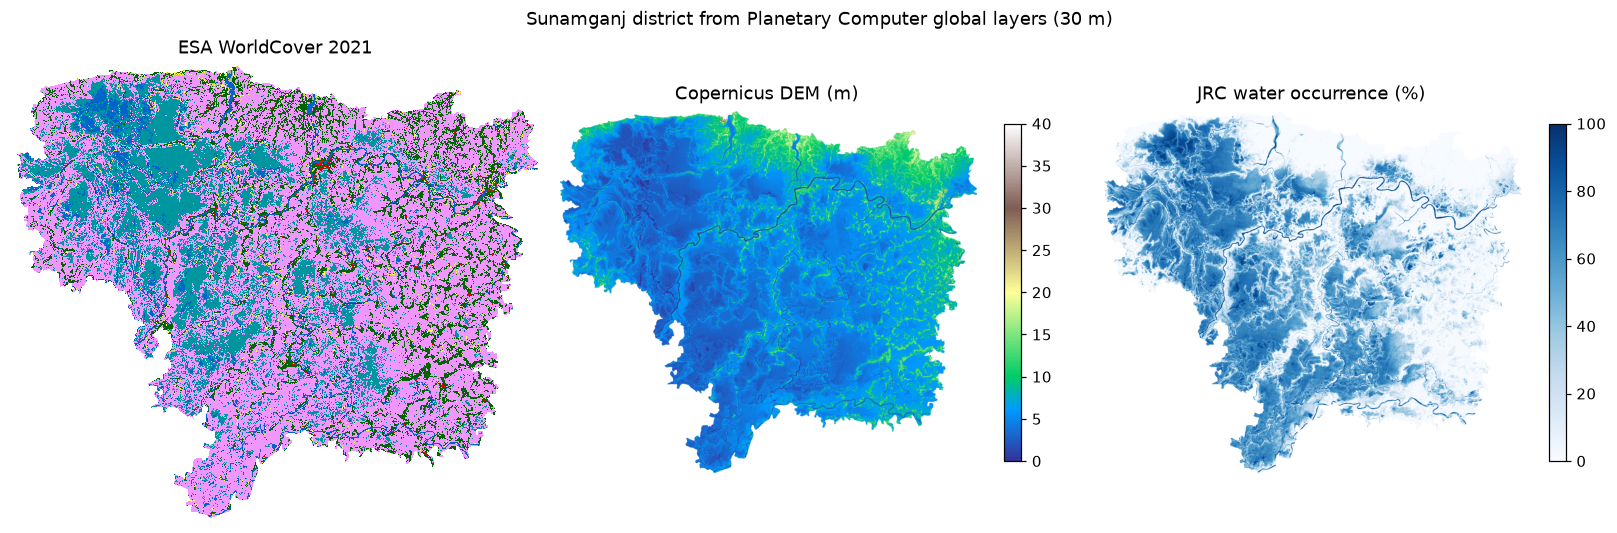

In [8]:
# Side-by-side maps of land cover, elevation, and long-term water occurrence
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
cmap = plt.matplotlib.colors.ListedColormap(["#006400", "#ffbb22", "#ffff4c", "#f096ff", "#fa0000", "#b4b4b4", "#f0f0f0", "#0064c8", "#0096a0", "#00cf75", "#fae6a0"])
lc_img = np.where(inside, g0.values, np.nan)
codes = np.array(sorted(classes))
idx = np.searchsorted(codes, np.nan_to_num(lc_img, nan=10)).astype(float); idx[~inside] = np.nan
ax[0].imshow(idx, cmap=cmap, vmin=-0.5, vmax=10.5, interpolation="nearest"); ax[0].set_title("ESA WorldCover 2021")
im = ax[1].imshow(np.where(inside, grids["cop-dem-glo-30"].values, np.nan), cmap="terrain", vmin=0, vmax=40); ax[1].set_title("Copernicus DEM (m)")
fig.colorbar(im, ax=ax[1], shrink=0.7)
im = ax[2].imshow(np.where(inside, occ_grid, np.nan), cmap="Blues", vmin=0, vmax=100); ax[2].set_title("JRC water occurrence (%)")
fig.colorbar(im, ax=ax[2], shrink=0.7)
for a in ax:
    a.set_axis_off()
plt.suptitle("Sunamganj district from Planetary Computer global layers (30 m)"); plt.tight_layout(); plt.show()


Three global layers describe Sunamganj (3,693 km²) without processing a single image:

- **Land cover:** cropland 57.6%, herbaceous wetland 21.4%, tree cover 12.7%, permanent water 6.5%.
- **Elevation:** a median of only 5.1 m, with 90% of the district below 9.8 m.
- **Surface water:** 78.7% of the district was water at some time between 1984 and 2020, and 36.4%
  is water at least half the time.

Most of the cropland is therefore seasonally flooded: haor fields carry one Boro rice crop in the dry
season and lie under water in the monsoon, the cycle seen in the NDVI series of Notebook 08_06. The
DEM took longest to load (19.5 s, four 1° tiles at full 30 m resolution); the single-tile layers
took about 3 s each.

## Server-side processing with openEO

openEO is an open standard API for Earth observation processing, implemented by several back ends,
including the Copernicus Data Space Ecosystem. A client builds a **process graph** (load a
collection, filter, compute NDVI, reduce over time) and sends it to the back end, which runs it next
to the data and returns only the result. Discovery works without an account.

In [9]:
# Connect to Copernicus openEO and describe available collections and processes
t0 = time.perf_counter()
con = openeo.connect("https://openeo.dataspace.copernicus.eu")
collections = con.list_collection_ids()
processes = con.list_processes()
s2 = con.describe_collection("SENTINEL2_L2A")
print(f"connected in {time.perf_counter() - t0:.1f} s: {len(collections)} collections, {len(processes)} processes")
print("SENTINEL2_L2A temporal extent:", s2["extent"]["temporal"]["interval"][0], "| bands:", len(s2["cube:dimensions"]["bands"]["values"]))

# Build a process graph for clear-sky median NDVI (not executed yet)
cube_oe = con.load_collection("SENTINEL2_L2A", spatial_extent=dict(zip(["west", "south", "east", "north"], AOI)),
                              temporal_extent=["2024-01-01", "2024-03-31"], bands=["B04", "B08", "SCL"], max_cloud_cover=20)
scl = cube_oe.band("SCL")
clear_oe = (scl == 4) | (scl == 5)
ndvi_oe = cube_oe.ndvi(red="B04", nir="B08").mask(~clear_oe).reduce_dimension(dimension="t", reducer="median")
graph = json.loads(ndvi_oe.to_json())["process_graph"]
print(f"process graph: {len(graph)} nodes ->", [n["process_id"] for n in graph.values()])
_ = (OUT / "openeo_ndvi_median.json").write_text(ndvi_oe.to_json())


connected in 7.3 s: 138 collections, 146 processes
SENTINEL2_L2A temporal extent: ['2015-06-27T10:25:31Z', None] | bands: 21


process graph: 5 nodes -> ['load_collection', 'ndvi', 'reduce_dimension', 'mask', 'reduce_dimension']


In [10]:
# Execution needs a (free) CDSE account. Set GEOLATTICE_OPENEO=1 after `con.authenticate_oidc()` has been done once
# interactively; the stored refresh token is then reused.
if os.environ.get("GEOLATTICE_OPENEO") == "1":
    con.authenticate_oidc()
    t0 = time.perf_counter()
    ndvi_oe.download(OUT / "openeo_ndvi_median.tif", format="GTiff")
    print(f"openEO result downloaded in {time.perf_counter() - t0:.0f} s")
else:
    print("openEO execution skipped (no account configured). The process graph above is complete and can be run as is.")


openEO execution skipped (no account configured). The process graph above is complete and can be run as is.


Without an account, openEO on Copernicus Data Space exposed 138 collections and 146 processes, and
accepted the composite of Section 5 as a five-node process graph:

1. load the collection;
2. compute NDVI;
3. reduce the scene classification band;
4. mask clouds;
5. take the median over time.

The graph, saved as JSON, is the complete, portable description of the analysis. Any openEO back
end that offers the collection can run it. Execution, the only step that needs an account, was
skipped here, as was the Earth Engine computation below.

## Google Earth Engine

Earth Engine works the same way: Python objects describe a computation, which runs on Google's
servers when a result is requested. It needs a Google Cloud project registered for Earth Engine
(free for research and non-commercial use) and a one-time `ee.Authenticate()`. The cell runs only
when a project is configured in `EE_PROJECT`; the code is the Earth Engine version of Section 5.
Note that Earth Engine's `COPERNICUS/S2_SR_HARMONIZED` collection has already removed the offset
of Section 4, another provider convention to check.

In [11]:
# Optional Earth Engine run when EE_PROJECT is set in the environment
project = os.environ.get("EE_PROJECT")
try:
    if not project:
        raise RuntimeError("EE_PROJECT is not set")
    ee.Initialize(project=project)
    region = ee.Geometry.Rectangle(AOI)

    # Mask cloudy pixels and compute NDVI on Sentinel-2 SR
    def mask_and_ndvi(img):
        scl = img.select("SCL")
        clear = scl.eq(4).Or(scl.eq(5))
        return img.normalizedDifference(["B8", "B4"]).rename("ndvi").updateMask(clear)

    col = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(region)
           .filterDate("2024-01-01", "2024-04-01").filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20)))
    median = col.map(mask_and_ndvi).median()
    stats = median.reduceRegion(ee.Reducer.median(), region, scale=10, maxPixels=1e9).getInfo()
    print(f"Earth Engine: {col.size().getInfo()} images; median NDVI {stats['ndvi']:.3f} "
          f"(odc-stac on Planetary Computer: {float(composite.median()):.3f})")
except Exception as exc:
    print(f"Earth Engine skipped: {exc}. To run it: create a Cloud project registered for Earth Engine, "
          "run ee.Authenticate() once, and set EE_PROJECT.")


Earth Engine skipped: EE_PROJECT is not set. To run it: create a Cloud project registered for Earth Engine, run ee.Authenticate() once, and set EE_PROJECT.


## Choosing a platform

| Question | Catalogue + own compute (PC, Earth Search, CDSE files) | Earth Engine | openEO |
|---|---|---|---|
| Who handles data access and scaling? | You (Notebook 08_08) | Google | The back end |
| How portable is the analysis? | High: STAC, COG, xarray work everywhere | Low: Earth Engine API only | Medium: one standard, several back ends |
| Custom algorithms (deep learning, any Python library) | Anything | Limited to its operations (plus exported data) | Limited to its processes (plus user-defined functions) |
| Getting results out | You already have the arrays | Export tasks to Drive / Cloud Storage | Download or batch jobs |
| Reproducibility | Pin item IDs and library versions | Collections and algorithms change server-side | Process graphs are explicit JSON |
| Cost model | Your compute; free data | Free (non-commercial) or licensed | Credits, free tier |
| Best for | Custom, reproducible, portable work; small to large areas | Fast global analyses with standard operations | European infrastructure, standard workflows, multi-back-end |

Whichever you use, check the data conventions (Section 4): the same "Sentinel-2 L2A" differs in
offsets, harmonisation, processing version and cloud masks between providers.

## Summary and exercises

**Key ideas**

- Catalogue platforms (STAC + COG) bring the data to your code; server-side platforms bring your
  code to the data.
- The same product can carry different values on different platforms; read the processing baseline
  and the provider's offset convention before mixing sources.
- odc-stac loads only the bands, area and resolution you ask for, lazily, from any STAC API.
- Global analysis-ready layers (WorldCover, Copernicus DEM, JRC water) answer many questions without
  processing imagery at all.
- openEO and Earth Engine express the analysis as a graph run by the provider; discovery and graph
  building are free, execution needs an account.

**What we found**

- **The catalogues:** Planetary Computer, Earth Search and Copernicus Data Space found the same 6
  dates over Bogra, but returned different item counts (7, 6, 6), identifiers and file locations.
- **The offset:** Planetary Computer's Sentinel-2 DN are 1,000 higher than Earth Search's for the
  same scene. Ignoring the offset cut median NDVI from 0.406 to 0.224; applying Earth Search's
  metadata offset made 77% of NDVI values impossible.
- **The composite:** odc-stac built a cloud-masked composite of 9 dates at 10 m in 18.5 s.
- **Sunamganj:** 57.6% cropland, a median elevation of 5.1 m, and 78.7% of the district water at some
  time since 1984.
- **openEO and Earth Engine:** the openEO graph was built (5 nodes) and the Earth Engine code was
  written; both need accounts to execute.

**Exercises**

1. Repeat Section 4 for a scene from 2021 (processing baseline 03.xx). What changes?
2. Build the composite of Section 5 from Earth Search instead of Planetary Computer with odc-stac.
   Which band names and offset handling must change? Compare the two composites pixel by pixel.
3. Compute the share of Sunamganj that is cropland *and* water at least 25 % of the time. What does it
   say about Boro rice in the haors?
4. Add Sentinel-1 RTC (`sentinel-1-rtc` on Planetary Computer) for August 2024 and map open water in
   Sunamganj by thresholding VV backscatter (Notebook 08_11 does this in full).
5. With a CDSE account, run the openEO graph of Section 7 and compare its median NDVI with Section 5.

**References**

- Microsoft Planetary Computer. https://planetarycomputer.microsoft.com
- Earth Search by Element 84. https://element84.com/earth-search/
- Copernicus Data Space Ecosystem. https://dataspace.copernicus.eu
- Schramm, M. et al. (2021). The openEO API: Harmonising the use of Earth observation cloud services using virtual data cube functionalities. *Remote Sensing*, 13(6), 1125.
- Gorelick, N. et al. (2017). Google Earth Engine: Planetary-scale geospatial analysis for everyone. *Remote Sensing of Environment*, 202, 18-27.
- ESA (2022). Sentinel-2 processing baseline 04.00: provision of negative radiometric values (BOA_ADD_OFFSET).
- Zanaga, D. et al. (2022). ESA WorldCover 10 m 2021 v200. Zenodo.
- Pekel, J.-F. et al. (2016). High-resolution mapping of global surface water and its long-term changes. *Nature*, 540, 418-422.